# Этап 11. Проверка устойчивости и итоговый выбор модели

## 1. Постановка исследования

**Цель:** проверить, насколько типология 2016 муниципалитетов за 24 месяца воспроизводима при небольших изменениях графа, признакового пространства, случайного состояния и временной регуляризации. Основной кандидат предыдущих этапов — **Temporal K-Means** на месячном CLR-пространстве, граф **union kNN, $k=10$**, $\beta=0{,}15$, $\lambda=0{,}25$.

Исходная оценка этапа 09 уже сравнила K-Means, Leiden, Spectral и временную модель; этап 10 интерпретировал четыре потребительско-экономических типа. **Мы не повторяем полный подбор алгоритмов** и не меняем исходные данные или последовательность идентификаторов.

Проверки в этом ноутбуке имеют разную область действия: для структуры графа и $\lambda$ — все 24 месяца; для сравнительных ICVI — четыре заранее заданных контрольных месяца; годовой эксперимент — один ретроспективный срез. Они не должны безоговорочно сводиться в один рейтинг.

## 2. Математические критерии и ограничения

**Устойчивость к изменению разбиения.** Для базового $g_t^{(0)}$ и альтернативного $g_t^{(c)}$ используем **Adjusted Rand Index (ARI)** и **Normalized Mutual Information (NMI)**, инвариантные к переименованию меток:

$$
\operatorname{ARI}=\frac{\operatorname{RI}-\mathbb E[\operatorname{RI}]}{1-\mathbb E[\operatorname{RI}]},\qquad
\operatorname{NMI}=\frac{2I(g^{(0)};g^{(c)})}{H(g^{(0)})+H(g^{(c)})}.
$$

Здесь $\operatorname{RI}$ — Rand index, $I$ — взаимная информация, $H$ — энтропия. Выше — более согласованные разбиения. Все сравнения проводятся **на одних и тех же муниципалитетах и месяцах**.

**Временная устойчивость:** медиана $\operatorname{ARI}(g_{t-1},g_t)$ и доля смены метки после согласования названий типов. Высокая устойчивость *не равна* качеству, поэтому отдельно проверяем, больше ли месячные изменения CLR у переключившихся муниципалитетов.

**Графовая устойчивость:** $J(E_t,E_t')=|E_t\cap E_t'|/|E_t\cup E_t'|$. Изменение $k$ в обычном K-Means не меняет его ответ; здесь $k$ влияет на **графовую составляющую временной модели** через $\beta$. Для $k=8,12$ строятся временные графы в памяти, а результаты сравниваются с исходным $k=10$.

**Временная модель:**

$$
\min_{g}\ \sum_{i,t}U_{i,t}(g_{i,t};X_t,G_t,\beta)+
\lambda\sum_{i,t>1}\mathbf 1\{g_{i,t}\ne g_{i,t-1}\}.
$$

$U_{i,t}$ — стоимость назначения на основании месячного центроида и распределения весов соседей (реализация `run_lambda_grid` этапа 08); $\lambda$ — штраф за переход. Это ретроспективная регуляризация, а не прогноз по данным, доступным в конкретном месяце.

Годовой слой `X_annual` анализируется отдельно на общем наборе полных наблюдений. Пока отсутствует доказательство публикационной доступности показателей в целевой месяц; поэтому результат **не участвует в выборе финальной as-of модели**. `X_delta` остаётся только внешним объясняющим набором этапа 10.

In [1]:
from pathlib import Path
import json, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score

ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.feature_analysis import parse_dynamic_columns
from src.graph_construction import feature_at, build_graph, edge_jaccard
from src.cluster_models import read_graph_sequence, run_partition
from src.cluster_validation import load_saved_partitions, evaluate_partition, monthly_summary
from src.temporal_analysis import (
    raw_labels, align_history, run_lambda_grid, features_by_month
)
from src.annual_attribution import prepare_lagged_annual, balanced_blocks
from src.model_robustness import (
    validate_candidate, compare_partitions, seed_repeatability,
    model_diagnostics, annual_expost_separation, final_metadata, save_final,
    temporal_kmeans_repeat
)

cfg = json.loads((ROOT/'configs'/'clustering_experiment.json').read_text(encoding='utf-8'))
rcfg = cfg['robustness_11']; tcfg = cfg['temporal_08']
X_dynamic = pd.read_parquet(ROOT/cfg['feature_path'])
mapping = parse_dynamic_columns(X_dynamic)
months = [str(m) for m in sorted({m for m,_ in mapping})]
assert len(months) == 24 and X_dynamic.index.is_unique and len(X_dynamic) == 2016
manifest = json.loads((ROOT/cfg['graph_directory']/'manifest.json').read_text(encoding='utf-8'))
assert all(manifest.get(key) == val for key,val in
           {'method':'union','k':10,'representation':'clr','window':1}.items())
graphs = read_graph_sequence(ROOT/cfg['graph_directory'], X_dynamic.index, months)
partitions, temporal_metadata = load_saved_partitions(
    ROOT/cfg['output_directory'], ROOT/tcfg['output_directory'],
    X_dynamic.index, months, include_temporal=True)
if temporal_metadata['temporal_status'] != 'loaded':
    raise FileNotFoundError('Необходимо сначала сохранить итоговые метки этапа 08')
assert np.isclose(temporal_metadata['temporal_selected_lambda'],float(tcfg['selection']))
base = partitions[rcfg['reference_model']]
features = features_by_month(X_dynamic, mapping, months, cfg['zero_floor'])
reference, _ = align_history(
    raw_labels(pd.read_parquet(ROOT/cfg['output_directory']/'labels.parquet'), months, 'kmeans'),
    min_jaccard=tcfg['matching_min_jaccard'],
    event_fraction=tcfg['event_min_fraction'],
    min_event_size=tcfg['event_min_size'])
validate_candidate(reference, base)
pilot_months = [months[i] for i in rcfg['pilot_month_indices']]
print('МО:',len(X_dynamic),'| месяцы:',months[0], '—',months[-1])
print('Финальная модель пока НЕ выбирается; базовая λ:', temporal_metadata['temporal_selected_lambda'])
print('Контрольные месяцы:',pilot_months)

МО: 2016 | месяцы: 2023-01 — 2024-12
Финальная модель пока НЕ выбирается; базовая λ: 0.25
Контрольные месяцы: ['2023-01', '2023-08', '2024-04', '2024-12']


## 3. Исходные результаты этапов 09–10

Предыдущие ICVI служат общей шкалой качества на месячных **CLR-признаках**: SW (↑), CH (↑), S_Dbw (↓), модулярность (↑), временные ARI/NMI (↑). Неопределённые S_Dbw исключаем из медиан и обязательно сообщаем число пропусков. AVI, AVU, MQ остаются вне оценки до получения официальных конкурсных определений.

Экономические названия типов и типичных муниципалитетов из этапа 10 подтверждаются *только если* существует сохранённый `cluster_interpretations.parquet`; иначе не приписываем им статус зафиксированной таблицы.

In [2]:
metrics09 = pd.read_parquet(ROOT / cfg['validation_09']['output_file'])
assert set(['method','month','sw','ch','s_dbw','modularity','ari_prev','nmi_prev']).issubset(metrics09.columns)
summary09 = monthly_summary(metrics09)
columns09 = ['months','invalid_months','sw_median','ch_median',
             's_dbw_median','modularity_median','ari_prev_median','nmi_prev_median',
             'largest_cluster_share_median']
print('Сводка подтверждённых результатов этапа 09:')
display(summary09[columns09].round(3))
print('Количество определённых S_Dbw:')
display(metrics09.groupby('method').s_dbw.agg(['count','size']))
interpretation_file = ROOT / cfg['interpretation_10']['output_directory'] / 'cluster_interpretations.parquet'
if interpretation_file.is_file():
    interpretations = pd.read_parquet(interpretation_file)
    print('Утверждённые названия типов этапа 10:')
    display(interpretations[['cluster','economic_type_name','interpretation_status']])
else:
    print('Таблица интерпретаций 10 пока не сохранена; используем только ранее рассчитанные профили как контекст.')

Сводка подтверждённых результатов этапа 09:


,months,invalid_months,sw_median,ch_median,s_dbw_median,modularity_median,ari_prev_median,nmi_prev_median,largest_cluster_share_median
method,,,,,,,,,
kmeans,24,0,0.299,1619.136,0.579,0.639,0.760,0.747,0.333
spectral,24,8,0.336,429.623,0.363,0.456,0.028,0.103,0.700
leiden,24,20,0.212,731.166,0.357,0.715,0.498,0.615,0.381


Количество определённых S_Dbw:


,count,size
method,,
kmeans,24,24
leiden,4,24
spectral,16,24


Утверждённые названия типов этапа 10:


,cluster,economic_type_name,interpretation_status
0,0,Продовольственно-ориентированный с умеренно по...,reviewed
1,1,Высокоплотный с повышенной оплатой труда и дол...,reviewed
2,2,Продовольственно-маркетплейсный с пониженными ...,reviewed
3,3,Промежуточный потребительский с умеренно повыш...,reviewed


## 4. Чувствительность к построению графа

При неизменных месячных CLR-признаках, базовых центроидах и $\lambda=0{,}25$ сравниваем входные графы с $k\in\{8,10,12\}$. Графы при $k=8,12$ создаются **только в памяти** через `build_graph`; ни один NPZ не записывается. Для каждого месяца вычисляется ARI/NMI относительно сохранённой временной модели $k=10$, а также Жаккар наборов рёбер. Это проверяет только зависимость **Temporal K-Means от графового окружения**, а не зависимость обычного K-Means.

In [3]:
chosen_lambda = float(tcfg['selection'])
base_grid, base_paths, emission_meta = run_lambda_grid(
    reference, features, graphs, rcfg['test_lambda'], graph_beta=tcfg['graph_beta'])
base_rebuilt = base_paths[chosen_lambda]
verification = compare_partitions(base, {'recomputed_same_config':base_rebuilt})
print('Проверка точного воспроизведения сохранённой модели (ARI):',
      verification.ari_to_reference.min())
if verification.ari_to_reference.min() < 1 - 1e-10:
    raise ValueError('Результат λ не совпадает с сохранённым этапом 08 — не продолжайте сравнение')

candidates = {'temporal_clr_k10_lambda_0.25': base}
comparison_graph = []; alternate_graph_sets = {}
for k in rcfg['graph_k_neighbors']:
    if not (1 <= int(k) < len(X_dynamic)) or int(k) == rcfg['baseline_k']:
        raise ValueError(f'Некорректное альтернативное k: {k}')
    alt_graphs = {m: build_graph(features[m], 'union', int(k))[0] for m in months}
    graph_j = [edge_jaccard(graphs[m],alt_graphs[m]) for m in months]
    _, paths, _ = run_lambda_grid(reference, features, alt_graphs,
                                  [0.0, chosen_lambda], graph_beta=tcfg['graph_beta'])
    name = f'temporal_clr_k{k}_lambda_0.25'
    candidates[name] = paths[chosen_lambda]
    alternate_graph_sets[name] = alt_graphs
    comparison_graph.append({'k':int(k), 'edge_jaccard_median':float(np.median(graph_j)),
                             'edge_jaccard_min':float(np.min(graph_j))})
    print('Проверена временная модель на k =',k)

per_month_agreement = compare_partitions(base,{k:v for k,v in candidates.items() if v is not base})
print('Сходство итоговых разбиений с k=10:')
display(per_month_agreement.groupby('configuration')[['ari_to_reference','nmi_to_reference']]
        .agg(['median','min']).round(3))
display(pd.DataFrame(comparison_graph).round(3))

Проверка точного воспроизведения сохранённой модели (ARI): 1.0
Проверена временная модель на k = 8
Проверена временная модель на k = 12
Сходство итоговых разбиений с k=10:


ari_to_reference        nmi_to_reference       
                                       median    min           median    min
configuration                                                               
temporal_clr_k12_lambda_0.25            0.999  0.992            0.997  0.985
temporal_clr_k8_lambda_0.25             0.998  0.996            0.997  0.992

,k,edge_jaccard_median,edge_jaccard_min
0,8,0.802,0.799
1,12,0.834,0.832


## 5. Временная регуляризация и сохранение реальных изменений

Проверяем $\lambda\in\{0,0{,}25,0{,}5\}$ на одних и тех же базовых графах и признаках. Сравниваем не только долю сохранения типа, но и качество соответствия исходным расходам, модулярность и отношение медианных изменений CLR у переключившихся/непереключившихся муниципалитетов. При росте $\lambda$ снижение числа переходов **не является самостоятельным доказательством улучшения**.

In [4]:
for lam in rcfg['test_lambda']:
    if np.isclose(lam, chosen_lambda):
        continue
    candidates[f'temporal_clr_k10_lambda_{lam:g}'] = base_paths[float(lam)]

reference_emission = base_grid.set_index('lambda')
print('Проверка временной регуляризации:')
display(base_grid[['lambda','stay_share_median','ari_adjacent_median',
                   'modularity_median','emission_cost_vs_reference',
                   'ari_to_independent_median']].round(3))

Проверка временной регуляризации:


,lambda,stay_share_median,ari_adjacent_median,modularity_median,emission_cost_vs_reference,ari_to_independent_median
0,0.00,0.906,0.760,0.639,1.000,0.994
1,0.25,0.941,0.848,0.637,1.002,0.955
2,0.50,0.957,0.887,0.631,1.007,0.927


## 6. Повторные запуски и альтернативное пространство признаков

Проверяем три значения `random_state` при неизменных гиперпараметрах. Для каждого запуска кластеры сначала независимо сопоставляются с эталонными типами соответствующего месяца методом Hungarian, затем применяется одинаковая временная регуляризация. Критерии — попарные ARI и NMI за 24 месяца.

Альтернативное представление `raw` проверяется на тех же графах $k=10$ при неизменном числе кластеров и $\lambda=0{,}25$. Таким образом, сравнение изолирует влияние атрибутов на разбиение, но не оценивает самостоятельный граф, построенный из raw-признаков.

In [5]:
seed_paths = {int(rcfg['seeds'][0]): base}
for seed in rcfg['seeds'][1:]:
    seed_paths[int(seed)] = temporal_kmeans_repeat(
        reference, features, graphs, cfg['selected_parameters']['kmeans'],
        seed, chosen_lambda, tcfg['graph_beta']
    )
repeats = seed_repeatability(seed_paths)
print('Случайная устойчивость:')
display(repeats[['ari', 'nmi']].agg(['median', 'min']).round(3))

raw_features = {
    month: feature_at(X_dynamic, mapping, month, 1, 'raw', cfg['zero_floor'])
    for month in months
}
candidates['temporal_raw_k10_lambda_0.25'] = temporal_kmeans_repeat(
    reference, raw_features, graphs, cfg['selected_parameters']['kmeans'],
    rcfg['seeds'][0], chosen_lambda, tcfg['graph_beta']
)
print('Чувствительность к raw-признакам:')
display(compare_partitions(
    base, {'raw': candidates['temporal_raw_k10_lambda_0.25']}
)[['ari_to_reference', 'nmi_to_reference']].agg(['median', 'min']).round(3))

Случайная устойчивость:


,ari,nmi
median,0.992,0.987
min,0.460,0.573


Чувствительность к raw-признакам:


,ari_to_reference,nmi_to_reference
median,0.302,0.373
min,0.228,0.312


## 7. Годовые данные: отдельно от финального выбора

Ограниченный **ретроспективный** опыт на декабрь 2024 года использует восемь показателей **2023 года** и те же наблюдения, у которых нет пропусков по годовому блоку. Сопоставляем $\alpha\in\{1,0{,}75,0{,}5\}$ в нормированной двухблочной матрице, без смешивания с `X_delta`. Для всех $\alpha$ оцениваем Silhouette в *одном* CLR-пространстве, а также ARI относительно базового разбиения **на том же подмножестве**.

$$
Z_i(\alpha)=\left[\sqrt{\alpha}\,\widetilde{\operatorname{clr}(x_i)},\;
\sqrt{1-\alpha}\,\widetilde a_{i,2023}\right].
$$

Два блока нормированы по сумме дисперсий, а годовой — после обоснованного логарифмирования положительных величин и робастного масштабирования. Из-за непроверенных дат публикации БДМО эти результаты **не являются as-of валидацией** и не могут служить основанием для окончательного использования годовых признаков в графах января–декабря 2024 года.

In [6]:
annual = pd.read_parquet(ROOT/cfg['annual_07a']['annual_path'])
if not annual.index.equals(X_dynamic.index):
    raise ValueError('Идентификаторы X_annual отличаются от X_dynamic')
period = rcfg['annual_snapshot']
ann_scaled, ann_mask, _ = prepare_lagged_annual(
    annual, period, int(rcfg['annual_lagged_year']),rcfg['annual_min_complete_cases'])
clr_common = features[period].loc[ann_mask]
assert clr_common.index.equals(ann_scaled.index)
exp_rows=[]; annual_partitions={}
for alpha in rcfg['annual_alphas']:
    Z = balanced_blocks(clr_common,ann_scaled,float(alpha))
    label = KMeans(n_clusters=int(cfg['selected_parameters']['kmeans']),
                   random_state=int(rcfg['seeds'][0]), n_init=10).fit_predict(Z)
    annual_partitions[float(alpha)] = label
base_alpha = annual_partitions[1.0]
for alpha, lab in annual_partitions.items():
    exp_rows.append({'alpha':alpha,'n_complete':len(clr_common),
                     'share_complete':float(len(clr_common)/len(X_dynamic)),
                     'ari_to_alpha1_same_sample':float(adjusted_rand_score(base_alpha,lab)),
                     'sw_on_clr_same_sample':float(silhouette_score(clr_common.to_numpy(float),lab))})
annual_sensitivity=pd.DataFrame(exp_rows)
print('Ограниченный ex-post эксперимент с X_annual:')
display(annual_sensitivity.round(3))
print('Покрытие базовых кластеров полными годовыми данными:')
display(pd.DataFrame({'cluster':base[period], 'complete':ann_mask})
        .groupby('cluster')['complete'].agg(['mean','sum','count']).round(3))

# Внешняя экономическая интерпретируемость кандидатов, НЕ внутренняя ICVI:
annual_eta = annual_expost_separation(annual,candidates,month=period,year=2024)
display(annual_eta.round(3))

Ограниченный ex-post эксперимент с X_annual:


,alpha,n_complete,share_complete,ari_to_alpha1_same_sample,sw_on_clr_same_sample
0,1.00,1784,0.885,1.000,0.274
1,0.75,1784,0.885,0.627,0.263
2,0.50,1784,0.885,0.368,0.278


Покрытие базовых кластеров полными годовыми данными:


,mean,sum,count
cluster,,,
0,0.920,599,651
1,0.749,341,455
2,0.916,306,334
3,0.934,538,576


,configuration,eta2_rank_median,valid_indicators,min_n_observed
0,temporal_clr_k10_lambda_0,0.157,8,1840
1,temporal_clr_k10_lambda_0.25,0.158,8,1840
2,temporal_clr_k10_lambda_0.5,0.161,8,1840
3,temporal_clr_k12_lambda_0.25,0.158,8,1840
4,temporal_clr_k8_lambda_0.25,0.158,8,1840
5,temporal_raw_k10_lambda_0.25,0.130,8,1840


## 8. Единое сравнение и проверка компромиссов

Финальная сравнительная таблица разделяет: (а) медианные ICVI из **уже сохранённого полного этапа 09**, (б) структуру и временную устойчивость **24 месяцев** в альтернативных настройках, (в) **контрольные 4 месяца** для сопоставимых ICVI новых кандидатов и (г) внешнюю интерпретируемость по БДМО в одном отчётном срезе. Пропуски обозначают отсутствие измерения, а не нулевое качество.

Веса единого рейтинга не вводятся. Компактность и скорость повторения тоже учитываются: дополнительное построение 24 графов для каждого $k$ и повторы K-Means стоят дороже повторного применения сохранённой модели. **Изменённые графы оцениваются по модулярности на общем графе $k=10$**, чтобы избежать ложного прямого сравнения разных нормировок модульности.

Общая сводка (ICVI — только 4 контрольных месяца):


,configuration,sw_pilot,ch_pilot,s_dbw_valid_pilot,modularity_median,ari_adjacent_median,switch_share_median,ari_to_baseline,max_cluster_share_median,eta2_rank_median,new_kmeans_fits_per_variant,temporary_graphs_per_variant
0,temporal_clr_k10_lambda_0.25,0.303,1577.296,4,0.637,0.848,0.059,1.000,0.335,0.158,0,0
1,temporal_clr_k8_lambda_0.25,0.303,1577.515,4,0.637,0.848,0.059,0.998,0.335,0.158,0,24
2,temporal_clr_k12_lambda_0.25,0.303,1577.225,4,0.637,0.850,0.060,0.999,0.335,0.158,0,24
3,temporal_clr_k10_lambda_0,0.303,1580.858,4,0.639,0.760,0.094,0.957,0.333,0.157,0,0
4,temporal_clr_k10_lambda_0.5,0.302,1570.251,4,0.631,0.887,0.043,0.968,0.339,0.161,0,0
5,temporal_raw_k10_lambda_0.25,0.126,824.033,4,0.562,0.717,0.109,0.302,0.345,0.130,24,0
6,independent_clr_k10,0.303,1580.943,4,0.639,0.760,0.094,0.955,0.333,NaN,0,0


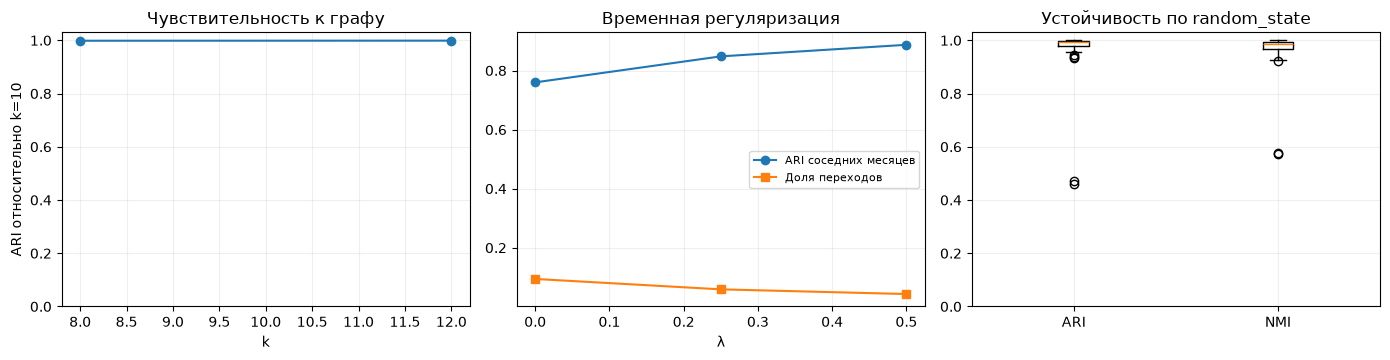

In [7]:
all_candidates = {**candidates, 'independent_clr_k10':reference}
agreement_all = compare_partitions(base,all_candidates)
diagnostics = model_diagnostics(all_candidates,features,graphs)
# Одинаковая CLR-геометрия и один и тот же граф для сравнительных ICVI.
pilot_rows=[]
for name, labels in all_candidates.items():
    for month in pilot_months:
        result=evaluate_partition(features[month],graphs[month],labels[month])
        pilot_rows.append({'configuration':name,'month':month,**result})
pilot=pd.DataFrame(pilot_rows)
pilot_summary=pilot.groupby('configuration').agg(
    sw_pilot=('sw','median'),ch_pilot=('ch','median'),
    s_dbw_pilot=('s_dbw','median'),s_dbw_valid_pilot=('s_dbw','count'))
robustness_summary=agreement_all.groupby('configuration').agg(
    ari_to_baseline=('ari_to_reference','median'),
    nmi_to_baseline=('nmi_to_reference','median'))
comparison=(diagnostics.set_index('configuration').join(robustness_summary)
            .join(pilot_summary).join(annual_eta.set_index('configuration'))
            .reset_index())
# Прозрачная модель добавочной вычислительной стоимости; без выдуманных секунд.
comparison['new_kmeans_fits_per_variant'] = comparison.configuration.map(
    lambda s: len(months) if s == 'temporal_raw_k10_lambda_0.25' else 0)
comparison['temporary_graphs_per_variant'] = comparison.configuration.map(
    lambda s: len(months) if s in alternate_graph_sets else 0)
comparison['calculation_scope'] = f'{len(months)} months / ICVI {len(pilot_months)} pilots'
print('Общая сводка (ICVI — только 4 контрольных месяца):')
shown=['configuration','sw_pilot','ch_pilot','s_dbw_valid_pilot','modularity_median',
       'ari_adjacent_median','switch_share_median','ari_to_baseline',
       'max_cluster_share_median','eta2_rank_median',
       'new_kmeans_fits_per_variant','temporary_graphs_per_variant']
display(comparison[shown].round(3))

fig, axes = plt.subplots(1,3,figsize=(14,3.7))
# 1. Устойчивость к размеру графа
k_test = per_month_agreement.copy()
k_test['k'] = k_test.configuration.str.extract(r'_k(\d+)_').astype(int)
axes[0].plot(k_test.groupby('k').ari_to_reference.median().index,
             k_test.groupby('k').ari_to_reference.median().values,marker='o')
axes[0].set(xlabel='k',ylabel='ARI относительно k=10',title='Чувствительность к графу',ylim=(0,1.03))
axes[0].grid(alpha=.2)
# 2. Регуляризация — устойчивость и переходы
axes[1].plot(base_grid['lambda'],base_grid['ari_adjacent_median'],marker='o',label='ARI соседних месяцев')
axes[1].plot(base_grid['lambda'],base_grid['switch_share_median'],marker='s',label='Доля переходов')
axes[1].set(xlabel='λ',title='Временная регуляризация')
axes[1].legend(fontsize=8);axes[1].grid(alpha=.2)
# 3. Случайная устойчивость
axes[2].boxplot([repeats['ari'].dropna(),repeats['nmi'].dropna()],tick_labels=['ARI','NMI'])
axes[2].set(title='Устойчивость по random_state',ylim=(0,1.03)); axes[2].grid(alpha=.2)
plt.tight_layout();plt.show()

## 9. Итоговый анализ устойчивости и выбор модели

Проверены все 24 месяца для временных и графовых сравнений, четыре контрольных месяца для ICVI новых конфигураций и три случайных состояния для повторных запусков. Результаты этапа 09 используются без переобучения первоначальных методов.

**9.1. Воспроизводимость и граф.** Сохранённая временная модель этапа 08 точно воспроизведена: минимальный ARI по месяцам равен **1,000**. При изменении числа соседей с $k=10$ до $k=8$ или $k=12$ медианные ARI относительно базовой модели равны соответственно **0,998** и **0,999** (минимумы **0,996** и **0,992**). При этом медианные коэффициенты Жаккара рёбер составляют **0,802** и **0,834**. Следовательно, в проверенном диапазоне состав кластеров намного менее чувствителен к небольшому изменению графа, чем само множество рёбер.

**9.2. Случайная устойчивость.** При попарном сравнении трёх `random_state` (11, 42, 73) по месяцам медианные **ARI = 0,992**, **NMI = 0,987**. Однако минимумы **ARI = 0,460**, **NMI = 0,573** указывают, что в части сравнений воспроизводимость заметно хуже. Поэтому корректен вывод о **высокой типичной, но не равномерной устойчивости**. Агрегированные outputs не позволяют установить конкретный месяц или пару запусков, ответственную за минимум; соответствующие строки можно вывести из рассчитанной таблицы `repeats` без повторной кластеризации.

**9.3. Временная регуляризация.** При переходе от $\lambda=0$ к $\lambda=0{,}25$ медианный ARI соседних месяцев возрастает с **0,760** до **0,848**, а доля переходов падает с **9,4%** до **5,9%**. Модулярность меняется с **0,639** до **0,637**, нормированная стоимость соответствия месячным признакам увеличивается примерно на **0,2%**. При $\lambda=0{,}5$ временной ARI достигает **0,887**, но доля переходов снижается до **4,3%**, модулярность — до **0,631**, а стоимость привязки к признакам растёт примерно на **0,7%**. Более сильное сглаживание не признаётся лучшим лишь за счёт меньшего числа переходов.

**9.4. Пространство признаков.** Изменение месячных CLR-признаков на исходные доли при сохранении графового слоя приводит к медианному ARI **0,302** относительно базовой модели. На общей CLR-геометрии четырёх контрольных месяцев SW снижается с **0,303** до **0,126**, а медианная модулярность — с **0,637** до **0,562**. Эта проверка изменяет атрибутивную часть модели **при фиксированном CLR-графе**, а не сравнивает две полностью независимо перестроенные сети. Вывод относится именно к исследованному варианту.

**9.5. Годовые показатели и экономический смысл.** Ретроспективный атрибутивный эксперимент доступен для **1784 из 2016** муниципалитетов (**88,5%**). При $\alpha=0{,}75$ и $\alpha=0{,}5$ ARI по отношению к чистому CLR на общем подмножестве равен **0,627** и **0,368** соответственно. При этом у экономического типа 1 полные годовые данные есть только у **74,9%** муниципалитетов. Убедительное улучшение не установлено, а неполнота и неизвестные даты публикации ограничивают использование годовых атрибутов в помесячной модели. `X_annual` остаётся средством экономической интерпретации, `X_delta` — описания межгодовых изменений.

**9.6. Сравнение алгоритмов.** По этапу 09 Spectral имеет более высокий медианный SW (**0,336**), Leiden — большую модулярность (**0,715**), тогда как Temporal K-Means обеспечивает медианный ARI соседних месяцев **0,848**, четыре интерпретированных типа и медианную долю крупнейшего кластера **33,5%**. У Spectral крупнейший кластер содержит около **70%** муниципалитетов. Для Leiden и Spectral S_Dbw определён только в **4** и **16** месяцах из 24; определения конкурсных AVI, AVU и MQ не подтверждены, поэтому полный конкурсный рейтинг по всем ICVI невозможен.

**Итоговое решение.** В качестве единой рабочей финальной конфигурации выбирается **Temporal K-Means**, четыре кластера, месячное **CLR**, **union kNN с $k=10$**, графовый коэффициент $\beta=0{,}15$, временной штраф $\lambda=0{,}25$, окно один месяц. Этот выбор основан на компромиссе геометрического качества, графовой структуры, временной согласованности, экономической интерпретируемости и стоимости вычислений; он **не является утверждением глобальной оптимальности или абсолютной случайной устойчивости**. Основные альтернативы: K-Means без временной регуляризации и Leiden как графовое разбиение.

**Ограничения:** модель ретроспективная, использует фиксированные месячные прототипы и приближённое графовое окружение; результаты не устанавливают причинных отношений и не представляют прогнозную as-of-валидацию. Названия экономических типов относятся только к выбранной конфигурации и проверенному соответствию меток этапа 10.

## 10. Фиксация модели для итоговой визуализации

Окончательно выбранная конфигурация: `temporal_clr_k10_lambda_0.25`. Функция сохранения записывает согласованные идентификаторы 2016 муниципалитетов за 24 месяца, компактную таблицу сравнения и JSON-параметры в `outputs/bdmo_v3/final_step11/`. Исходные признаки и графы повторно не сохраняются.

In [8]:
cfg = json.loads((ROOT / 'configs' / 'clustering_experiment.json').read_text(encoding='utf-8'))
rcfg = cfg['robustness_11']
selected_id = rcfg.get('final_selection')
if not rcfg.get('save_enabled', False) or selected_id is None:
    print('Итоговое сохранение выключено в секции robustness_11.')
else:
    if selected_id != 'temporal_clr_k10_lambda_0.25':
        raise ValueError('Выбрана непроверенная итоговая конфигурация')
    if selected_id not in all_candidates or selected_id in alternate_graph_sets:
        raise ValueError('Отсутствуют метки или графы выбранной конфигурации')
    if not np.isclose(verification.ari_to_reference.min(), 1.0):
        raise ValueError('Базовая модель этапа 08 не воспроизведена')
    if len(seed_paths) != len(rcfg['seeds']) or repeats.empty:
        raise ValueError('Не завершена проверка случайной устойчивости')
    print('Наименее согласованные сравнения random_state:')
    display(repeats.nsmallest(5, 'ari')[['seed_a', 'seed_b', 'month', 'ari', 'nmi']].round(3))
    final_info = final_metadata(cfg, selected_id, X_dynamic.index, months, comparison)
    final_info['random_state_stability'] = {
        'seeds': [int(s) for s in rcfg['seeds']],
        'n_pair_month_comparisons': int(len(repeats)),
        'ari_median': float(repeats.ari.median()),
        'ari_min': float(repeats.ari.min()),
        'nmi_median': float(repeats.nmi.median()),
        'nmi_min': float(repeats.nmi.min()),
        'n_ari_below_0_9': int((repeats.ari < 0.9).sum()),
        'limitation': 'Устойчивость высока в медиане, но не однородна по всем парам и месяцам.'
    }
    saved_paths = save_final(
        ROOT / rcfg['output_directory'], X_dynamic.index, months,
        all_candidates[selected_id], comparison, final_info
    )
    print('Итоговые артефакты сохранены:')
    for path in saved_paths:
        print('-', path.relative_to(ROOT))

Наименее согласованные сравнения random_state:


,seed_a,seed_b,month,ari,nmi
11,11,42,2023-12,0.460,0.573
35,11,73,2023-12,0.470,0.578
34,11,73,2023-11,0.935,0.922
10,11,42,2023-11,0.937,0.925
59,42,73,2023-12,0.944,0.928


Итоговые артефакты сохранены:
- outputs/bdmo_v3/final_step11/final_labels.parquet
- outputs/bdmo_v3/final_step11/robustness_comparison.parquet
- outputs/bdmo_v3/final_step11/final_model.json
